In [2]:
import sys
import os

print("Python executable:", sys.executable)
print("Python version:   ", sys.version.split()[0])
print("Virtual env:      ", os.environ.get("VIRTUAL_ENV", "❌ NONE (not a venv!)"))
print("Kernel name:      ", os.environ.get("JPY_PARENT_PYTHON", "n/a"))

Python executable: c:\Users\ycode\Desktop\2nd_YouCode\briefs\Classification_images_Deep_Learning\venv\Scripts\python.exe
Python version:    3.12.10
Virtual env:       C:\Users\ycode\Desktop\2nd_YouCode\briefs\Classification_images_Deep_Learning\venv
Kernel name:       n/a


# 02 — Prétraitement & Data Augmentation

**Objectif :** construire les pipelines `tf.data` (train / val / test) à partir
du split sauvegardé dans `data/splits.npz`, visualiser le prétraitement
(resize + normalisation), et vérifier la Data Augmentation appliquée
**uniquement au jeu d'entraînement**.

⚠️ On ne re-split PAS ici : le split est déjà figé dans `splits.npz`.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))

from src.data import (
    make_dataset,
    IMG_SIZE,
    BATCH_SIZE,
    SEED,
)

plt.rcParams["figure.figsize"] = (12, 6)

## 1. Chargement du split sauvegardé

On charge `data/splits.npz` — le même split que dans le notebook 01.
Aucune re-génération, aucune divergence possible.

In [3]:
splits = np.load("../data/splits.npz", allow_pickle=True)

X_train = splits["X_train"]
y_train = splits["y_train"]
X_val   = splits["X_val"]
y_val   = splits["y_val"]
X_test  = splits["X_test"]
y_test  = splits["y_test"]
class_names = list(splits["class_names"])

print(f"Train : {len(X_train):>6} images")
print(f"Val   : {len(X_val):>6} images")
print(f"Test  : {len(X_test):>6} images")
print(f"Classes : {class_names}")

Train :  11923 images
Val   :   2555 images
Test  :   2556 images
Classes : [np.str_('buildings'), np.str_('forest'), np.str_('glacier'), np.str_('mountain'), np.str_('sea'), np.str_('street')]


## 2. Construction des pipelines `tf.data`

- `make_dataset(..., training=True)` → shuffle + augment → **train**
- `make_dataset(..., training=False)` → deterministic → **val / test**

La normalisation `/255` et le resize sont faits **à la volée** dans le pipeline.

In [5]:
train_ds = make_dataset(X_train, y_train, training=True)
val_ds   = make_dataset(X_val,   y_val,   training=False)
test_ds  = make_dataset(X_test,  y_test,  training=False)

print("Batches train :", len(train_ds))
print("Batches val   :", len(val_ds))
print("Batches test  :", len(test_ds))

Batches train : 373
Batches val   : 80
Batches test  : 80


## 3. Vérification du prétraitement (resize + normalisation)

On récupère **un batch sans augmentation** (depuis `val_ds`) et on vérifie :
- shape attendue `(BATCH_SIZE, 150, 150, 3)` ;
- plage de valeurs `[0, 1]` (pas d'augmentation).

In [6]:
for images, labels in val_ds.take(1):
    print("Batch shape :", images.shape)
    print("Labels      :", labels.numpy()[:8], "...")
    print("Pixel range :", float(images.numpy().min()), "→", float(images.numpy().max()))

Batch shape : (32, 150, 150, 3)
Labels      : [4 0 3 2 5 3 5 2] ...
Pixel range : 0.0 → 1.0


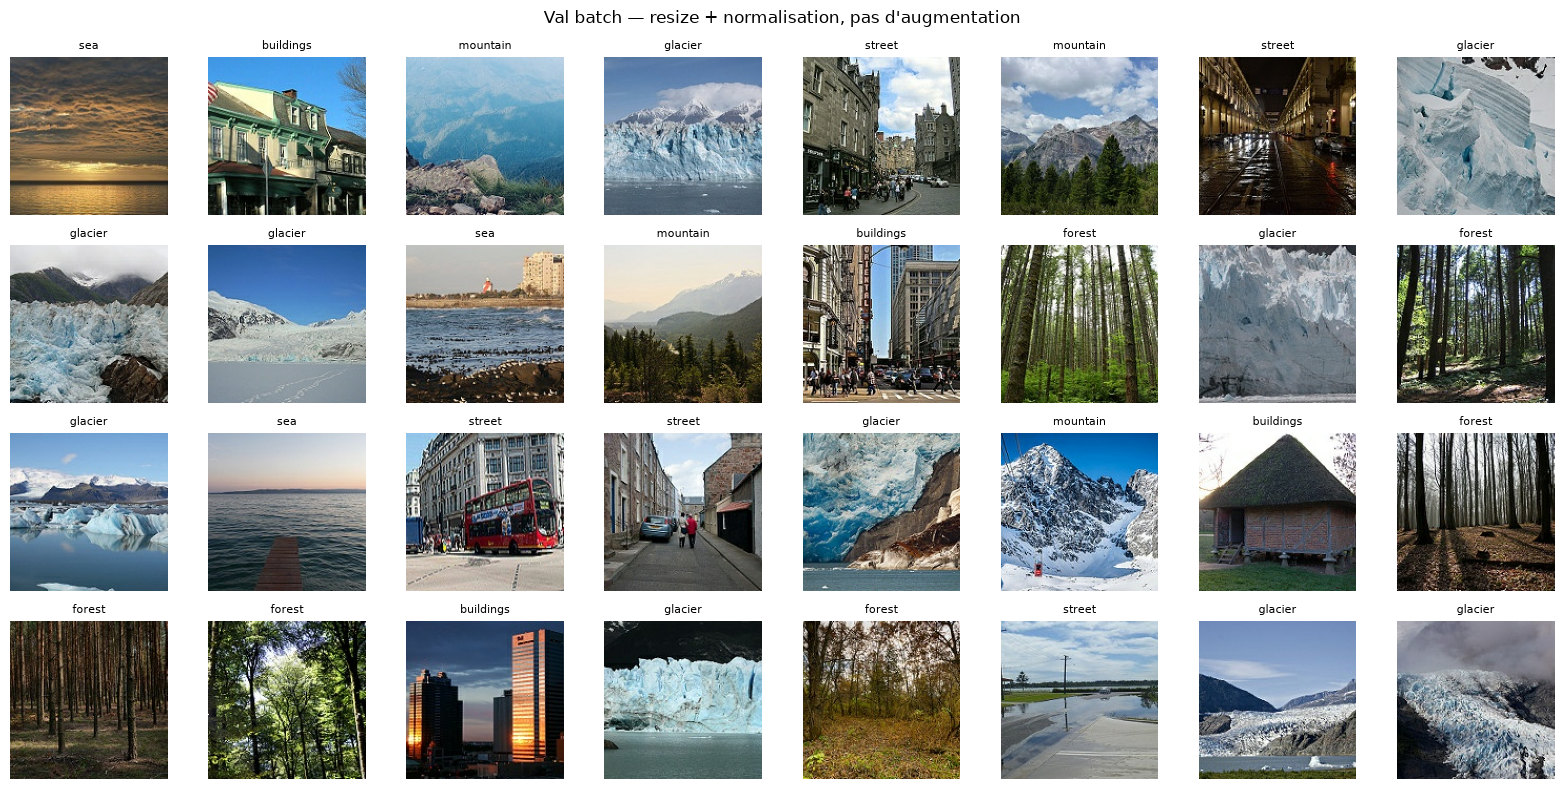

In [7]:
for images, labels in val_ds.take(1):
    fig, axes = plt.subplots(4, 8, figsize=(16, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i])
        ax.set_title(class_names[labels[i].numpy()], fontsize=8)
        ax.axis("off")
    plt.suptitle("Val batch — resize + normalisation, pas d'augmentation", fontsize=12)
    plt.tight_layout()
    plt.show()
    break

## 4. Comparaison AVANT / APRÈS augmentation

Pour montrer l'effet de la Data Augmentation, on prend **la même image**
et on la passe **plusieurs fois** dans la pipeline d'entraînement :
chaque passage applique des transformations aléatoires différentes.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0276965].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0501038].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0228041].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0178837].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0403254].


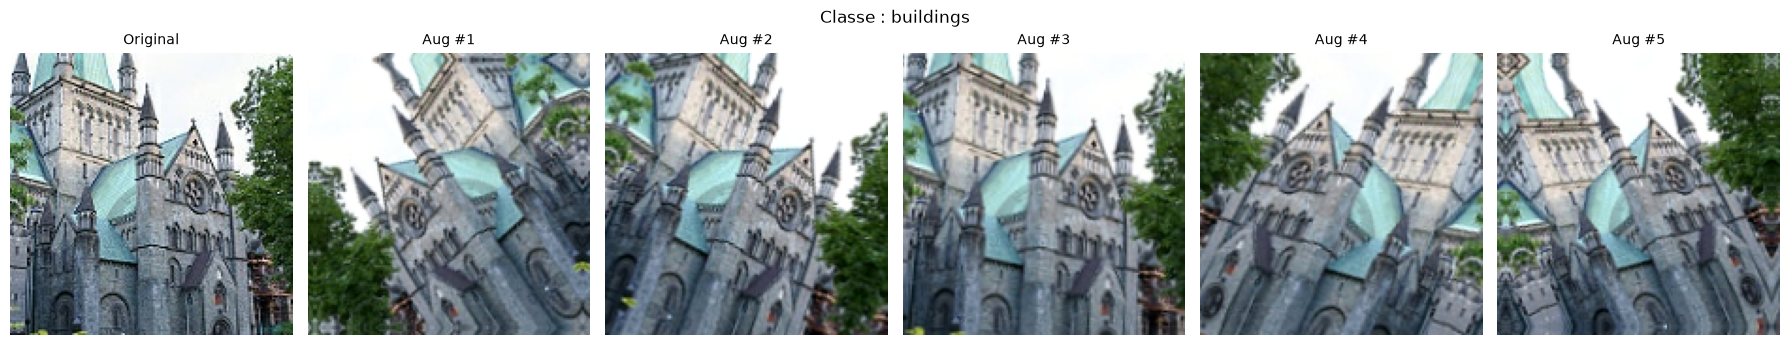

In [13]:
from src.data import load_and_preprocess, make_augmentation
import tensorflow as tf

# Pick ONE image
sample_path  = X_train[0]
sample_label = y_train[0]

# Load once (no augmentation)
img_clean, _ = load_and_preprocess(sample_path, sample_label)

# Build the augmentation layer (same one used in training)
augment = make_augmentation()

# Generate 5 augmented versions of the SAME image
augmented = []
for _ in range(5):
    aug_img = augment(tf.expand_dims(img_clean, 0), training=True)[0]
    augmented.append(aug_img.numpy())

# Plot: original + 5 augmented
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(img_clean.numpy())
axes[0].set_title("Original", fontsize=10)
axes[0].axis("off")

for i, aug_img in enumerate(augmented):
    axes[i + 1].imshow(aug_img)
    axes[i + 1].set_title(f"Aug #{i+1}", fontsize=10)
    axes[i + 1].axis("off")

plt.suptitle(f"Classe : {class_names[sample_label]}", fontsize=12)
plt.tight_layout()
plt.show()

## 5. Rôle de la Data Augmentation (pour le rapport)

La Data Augmentation **augmente artificiellement la diversité** du jeu
d'entraînement en appliquant des transformations aléatoires aux images.

**Pourquoi c'est utile :**
- **Réduit l'overfitting** : le modèle ne voit jamais exactement la même image.
- **Améliore la généralisation** : le modèle apprend des features invariantes
  (une "montagne" reste une montagne même légèrement tournée).
- **Simule des variations réelles** : caméra penchée, distance différente,
  luminosité variable.

**Pourquoi uniquement sur le train :**
- Val/test doivent être **déterministes** pour comparer les modèles équitablement.
- Augmenter val/test créerait des métriques non reproductibles.

**Transformations utilisées :**
| Transformation | Effet | Justification |
|----------------|-------|---------------|
| `RandomFlip("horizontal")` | Miroir gauche-droite | Les paysages sont symétriques horizontalement |
| `RandomRotation(0.1)` | ±10 % de 2π ≈ ±36° | Simule caméra légèrement penchée |
| `RandomZoom(0.1)` | ±10 % | Simule distance/zoom variable |
| `RandomContrast(0.1)` | ±10 % de contraste | Simule conditions lumineuses variables |


## ✅ Résumé

- Split chargé depuis `data/splits.npz` — identique au notebook 01.
- Pipelines construits : `train_ds`, `val_ds`, `test_ds`.
- Prétraitement : resize 150×150 + normalisation `[0, 1]`.
- Data Augmentation : 4 transformations, **train uniquement**.
- Visualisations : batch val (propre) + avant/après augmentation.